<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2011-20/Experiment%2015%3A%20BPTT%20Flow%20and%20Gradient%20Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

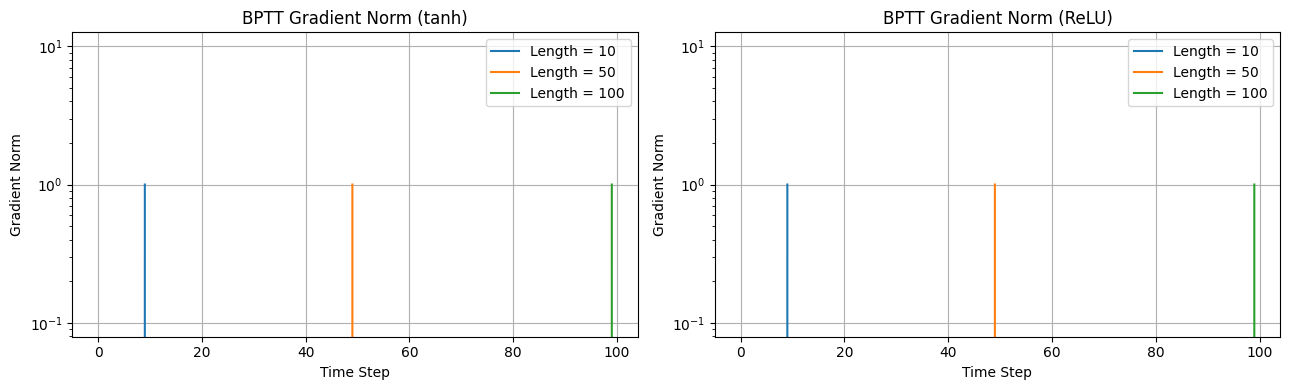

tanh gradients decay exponentially toward early steps (vanishing gradients), whereas ReLU gradients grow rapidly over long sequences (exploding gradients).


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

np.random.seed(42)
tf.random.set_seed(42)

prices = np.cumsum(np.random.normal(0.05, 1.0, 1100)) + 100
prices = (prices - prices.mean()) / prices.std()

def get_grad_norms(seq_len, act='tanh'):
    X = np.array([prices[i:i+seq_len] for i in range(32)]).reshape(32, seq_len, 1).astype(np.float32)
    y = prices[seq_len:seq_len+32].reshape(32, 1).astype(np.float32)

    rnn = keras.layers.SimpleRNN(16, activation=act, return_sequences=True)
    dense = keras.layers.Dense(1)

    with tf.GradientTape() as tape:
        h_seq = rnn(X)
        tape.watch(h_seq)
        pred = dense(h_seq[:, -1, :])
        loss = tf.reduce_mean(tf.square(y - pred))

    grads = tape.gradient(loss, h_seq).numpy()
    norms = np.linalg.norm(grads, axis=(0, 2))
    return norms / (norms[-1] + 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for L in [10, 50, 100]:
    axes[0].plot(get_grad_norms(L, 'tanh'), label=f'Length = {L}')
    axes[1].plot(get_grad_norms(L, 'relu'), label=f'Length = {L}')

axes[0].set_title("BPTT Gradient Norm (tanh)")
axes[1].set_title("BPTT Gradient Norm (ReLU)")
for ax in axes:
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Gradient Norm")
    ax.set_yscale('log')
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

print("tanh gradients decay exponentially toward early steps (vanishing gradients), whereas ReLU gradients grow rapidly over long sequences (exploding gradients).")